In [598]:
# !pip install gpytorch

In [1]:
import torch
import gpytorch
import matplotlib.pyplot as plt
import numpy as np
import copy

In [2]:
N_samples = [10, 11, 12, 13]
K = 4 # num tasks
d = 3

torch.manual_seed(12345)
# device = "cuda" if torch.cuda.is_available() else "cpu"
device = "cpu"
dtype = torch.float32

In [3]:
def make_inputs(N, d):
  return (torch.randn(N, d, device=device, dtype=dtype))

def q1_and_grad(X):
  x1, x2, x3 = X[:,0], X[:, 1], X[:, 2] # getting the task input val

  # q1 = 0.5(x1^2 + x2^2) + 0.1 x3^2
  val = 0.5*(x1**2 + x2**2) + 0.1 * x3**2
  
  grad = torch.stack([x1, x2, 0.2 * x3], dim = 1) # getting the grad and stack them in horizontal

  return val, grad

def q2_and_grad(X):
  x1, x2, x3 = X[:,0], X[:, 1], X[:, 2] # getting the task input val

# q2 = 0.5*[(x1 - 0.5)^2 + 2(x2 + 0.2)**2)) + 0.05 * x3^2]
  val = 0.5*((x1  - 0.5)**2 + (2*(x2 + 0.2)**2)) + 0.05 * (x3**2)
  
  
  grad = torch.stack([(x1 - 0.5), 2*(x2 + 0.2), 0.1*x3], dim = 1) # getting the grad and stack them in horizontal

  return val, grad

In [4]:
mixing = torch.tensor([
    [0.5, 0.1],
    [0.2, 0.4],
    [0.6, 0.4],
    [0.5, 0.2]

], device=device, dtype=dtype) # set the mixing matrix for 3 function

val_noise_std = torch.tensor([0.01, 0.01, 0.01, 0.01], device=device, dtype = dtype)
grad_noise_std = torch.tensor([0.01, 0.01, 0.01, 0.01], device=device, dtype=dtype)

In [5]:
#build the list input for the heterotopic case

X_list, Y_list, G_list = [], [], []

for t in range(K):
  X = make_inputs(N_samples[t], d) # getting the samples of each

  # getting the value and grad
  q1, gq1 = q1_and_grad(X)
  q2, gq2 = q2_and_grad(X)

  #mixing
  a, b = mixing[t, 0], mixing[t, 1]

  f = a*q1 + b*q2
  grad = a*gq1 + b*gq2

  y = f + val_noise_std[t] * torch.randn_like(f)
  grad_noisy = grad + grad_noise_std[t] * torch.randn_like(grad)

  X_list.append(X)
  Y_list.append(y)
  G_list.append(grad_noisy)

In [6]:
Y_list[0].view(-1, 1)


tensor([[1.3522],
        [0.1036],
        [0.8497],
        [1.4290],
        [0.2040],
        [0.6000],
        [0.1507],
        [0.0787],
        [0.2230],
        [2.1467]])

In [7]:
G_list[0].view(-1, d)

tensor([[-0.9406,  0.3888, -0.3184],
        [ 0.2341,  0.2771, -0.0093],
        [ 0.0662, -0.8524,  0.2735],
        [ 1.1478,  0.6057, -0.1312],
        [-0.1701,  0.5019,  0.0031],
        [ 0.6223, -0.5672, -0.1102],
        [-0.2846, -0.1478, -0.0971],
        [ 0.0021,  0.2295, -0.0548],
        [ 0.0269,  0.4915, -0.0765],
        [ 0.5693, -1.5974,  0.0212]])

In [8]:
G_list[0]

tensor([[-0.9406,  0.3888, -0.3184],
        [ 0.2341,  0.2771, -0.0093],
        [ 0.0662, -0.8524,  0.2735],
        [ 1.1478,  0.6057, -0.1312],
        [-0.1701,  0.5019,  0.0031],
        [ 0.6223, -0.5672, -0.1102],
        [-0.2846, -0.1478, -0.0971],
        [ 0.0021,  0.2295, -0.0548],
        [ 0.0269,  0.4915, -0.0765],
        [ 0.5693, -1.5974,  0.0212]])

In [9]:
y_mat = torch.cat([
      torch.cat([Y_list[0].view(-1,1), G_list[0].view(-1,d)], dim = 1)
  ], dim = 0)

In [10]:
# task_id = torch.cat([
#       torch.full((X.shape[0],), t, device=device, dtype=torch.long)
#       for t, X in enumerate(X_list)
#   ], dim = 0)

# val_var = (val_noise_std[task_id] ** 2) # (Ntot,)
# grad_var = (grad_noise_std[task_id] ** 2) # (Ntot,)

# noise_mat = torch.cat([val_var[:, None], grad_var[:, None].repeat(1, d)], dim=1) # return a matrix of the noise size (Ntot, d + 1)
# noise_vec = noise_mat.reshape(-1) # 1 vector inlcude all the observation for all task

In [11]:
# noise_mat

In [12]:
# noise_vec

In [18]:
## stack the data
## y_vec is interleaved perpoint

def build_stacked_dataset(X_list, Y_list, G_list, val_noise, grad_noise):
  d = X_list[0].shape[1] # getting input dim

  device = X_list[0].device
  dtype = X_list[0].dtype

  X_all = torch.cat(X_list, dim = 0) # concat all the data vertical

  # set the task id -> create the task id => shape equal with shape of the x_list (Ns ttotal)
  task_id = torch.cat([
      torch.full((X.shape[0],), t, device=device, dtype=torch.long)
      for t, X in enumerate(X_list)
  ], dim = 0)

  # combine the task_id and point

  X_aug = torch.cat([X_all, task_id.float().unsqueeze(1)], dim = 1) # (Ntotal, d + 1)

  # (Ntot, d+1) => we reshape and also stack the value + gradient

  y_mat = torch.cat([
      torch.cat([y.view(-1,1), g.view(-1,d)], dim = 1)
      for y, g in zip(Y_list, G_list)
  ], dim = 0)

  print(y_mat.shape)

  # stretiching

  y_vec = y_mat.reshape(-1) # 1 vector inlcude all the observation for all task

  # noise information
  val_var = (val_noise[task_id] ** 2) # (Ntot,)
  grad_var = (grad_noise[task_id] ** 2) # (Ntot,)

  noise_mat = torch.cat([val_var[:, None], grad_var[:, None].repeat(1, d)], dim=1) # reshape and concat to return a matrix of the noise size (Ntot, d + 1)
  noise_vec = noise_mat.reshape(-1) # 1 vector inlcude all the observation for all task ## here usig for fix noise,

  return X_aug, y_vec, noise_vec

## y_vec look like [y11 gd1_11 gd2_12 y12 gd1_12 gd2_12 ... y1N gd1_1N gd2_1N ... y21 gd1_21 gd2_21...y2N2 gd1_2N2 gd2_2N2... so on]
## same as the noise vec

In [19]:
X_aug, Y_vec, noise_vec = build_stacked_dataset(X_list, Y_list, G_list, val_noise_std, grad_noise_std)

torch.Size([46, 4])


In [15]:
N_tot = X_aug.shape[0]
print("train point total", N_tot, "and number of observation points",Y_vec.numel())

train point total 46 and number of observation points 184


In [17]:
Y_vec.shape[0]

184

In [614]:
X_aug.shape

torch.Size([46, 4])

In [615]:
task_id = X_aug[:,d]

In [616]:
task_id

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 1., 1., 1., 1., 1., 1., 1.,
        1., 1., 1., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 2., 3., 3., 3.,
        3., 3., 3., 3., 3., 3., 3., 3., 3., 3.])

In [617]:
#index kernel
idx_ker = gpytorch.kernels.IndexKernel(num_tasks=K, rank=1)

index_cov = idx_ker(task_id).to_dense()

In [618]:
index_cov.repeat_interleave((d+1), dim=0).repeat_interleave((d+1), dim=1).shape

torch.Size([184, 184])

In [619]:
class LMCGradKernel(gpytorch.kernels.Kernel):
    def __init__(self, num_tasks: int, input_dim: int, num_latents: int, rank: int):
      super().__init__()
      self.d = input_dim
      self.Q = num_latents # define number of the latent process using in the model

      self.task_kernels = torch.nn.ModuleList([
          gpytorch.kernels.IndexKernel(num_tasks=num_tasks, rank=rank)
          for _ in range(self. Q)
      ])

      #define the kernel of the latent process
      self.latent_grad_kernels = torch.nn.ModuleList([
          gpytorch.kernels.RBFKernelGrad(ard_num_dims=input_dim)
          for _ in range(self.Q)
      ])

    # key here since the normal the Kernel Moduele in GP do not allow to return the d + dim as output. here we are applying the nested layer of the MTGP
    # overwrite the number of output per input
    # val + partial derivative
    def num_outputs_per_input(self, x1=None, x2=None):
      return self.d + 1

    def forward(self, x1, x2, **params):
      d = self.d # input dim

      x1_data = x1[:, :d]
      x2_data = x2[:, :d]

      t1 = x1[:, d].long() ## getting the task id of each sample
      t2 = x2[:, d].long() ## just incase the task not the integet

      K = None

      for q in range(self.Q):

        # N1*(d+1), N2*(d+1)
        Kx = self.latent_grad_kernels[q](x1_data, x2_data, **params).to_dense() #get full tensors

        # print(Kx.shape)

        # task kernel

        Kt = self.task_kernels[q](t1, t2).to_dense() # need go dense since the pytorhc -> return the lazy tensor (here we want to get full tensor)

        #expand to big task kernel (repeat each tensor elemense d+1 times throught the vertical and also the horizontal axis)
        Kt_big = Kt.repeat_interleave(d+1, dim = 0).repeat_interleave(d+1, dim = 1)

        # multiply them together the Kx and Kt

        Kfull = Kx * Kt_big

        K = Kfull if K is None else (K + Kfull)

      return K

In [620]:
# covar_moduel = LMCGradKernel(num_tasks=4, input_dim=3, num_latents=3, rank=1)
# covar_moduel(X_aug, X_aug).shape

In [621]:
# define the share model
import torch.nn.functional as F
from linear_operator.operators import DiagLinearOperator

class ExactLCMGrad(gpytorch.models.ExactGP):
  def __init__(self, train_x, train_y, likelihood, num_tasks, input_dim, num_latents, rank):
    super().__init__(train_x, train_y, likelihood)

    self.d = input_dim
    self.K = num_tasks

    self.mean_module = gpytorch.means.ConstantMeanGrad()
    self.covar_module = gpytorch.kernels.ScaleKernel(
        LMCGradKernel(num_tasks, input_dim, num_latents, rank)
    )
    # self.covar_module = LMCGradKernel(num_tasks, input_dim, num_latents, rank)
    # actually do not need scale since we alreayd scale by the index kernel => not overparamterizing

    # each task will have 2 noises: val noise + grad noise
    self.raw_val_noise = torch.nn.Parameter(torch.zeros(num_tasks))
    self.raw_grad_noise = torch.nn.Parameter(torch.zeros(num_tasks))
    self.noise_floor = 1e-4

  def forward(self, x_aug):
    d = self.d

    x_data = x_aug[:, :d]

    t = x_aug[:, d].long() # Ntot

    mean_vec = self.mean_module(x_data).reshape(-1) #flat it (Ntot*(d+1),)

    covar_mtrx = self.covar_module(x_aug, x_aug) #(Ntot(d+1) x Ntot(d+1))

    # perpoint variance
    val_var = F.softplus(self.raw_val_noise[t]) + self.noise_floor #
    grad_var = F.softplus(self.raw_grad_noise[t]) + self.noise_floor #

    # expand to value and also gradient of each point for each task
    noise_mat = torch.cat([val_var[:, None], grad_var[:, None].repeat(1,d)],  dim=1)
    noise_vec = noise_mat.reshape(-1)

    cov_noise = covar_mtrx + DiagLinearOperator(noise_vec)

    return gpytorch.distributions.MultivariateNormal(mean_vec, cov_noise)

In [622]:
likelihood = gpytorch.likelihoods.GaussianLikelihood()
likelihood.noise = 1e-4 ## we need to fix the noise here very samll -> not affect our inject noise learning, since te gpytorch already buildin noise for each data poitns but they are identical
likelihood.raw_noise.requires_grad_(False) # do not include the noise and tunnig the noise of the likelihood

Parameter containing:
tensor([-inf])

In [623]:
model = ExactLCMGrad(X_aug, Y_vec, likelihood, num_tasks=K, input_dim=d, num_latents=4, rank=2)
state_before = copy.deepcopy(model.state_dict())

In [624]:
model.train()
likelihood.train()

optimizer = torch.optim.Adam(model.parameters(), lr=0.02)
mll = gpytorch.mlls.ExactMarginalLogLikelihood(likelihood, model)

iters = 300

for it in range(iters):
    optimizer.zero_grad()
    # prior
    out = model(X_aug)
    loss = -mll(out, Y_vec)

    loss.backward()
    optimizer.step()

    if (it + 1)%5 == 0:
        print(f"iter {it+1}/{iters} ----- Loss = {loss.item():.4f}")

iter 5/300 ----- Loss = 1.8618
iter 10/300 ----- Loss = 1.7076
iter 15/300 ----- Loss = 1.5618
iter 20/300 ----- Loss = 1.4263
iter 25/300 ----- Loss = 1.3019
iter 30/300 ----- Loss = 1.1885
iter 35/300 ----- Loss = 1.0854
iter 40/300 ----- Loss = 0.9918
iter 45/300 ----- Loss = 0.9066
iter 50/300 ----- Loss = 0.8288
iter 55/300 ----- Loss = 0.7568
iter 60/300 ----- Loss = 0.6895
iter 65/300 ----- Loss = 0.6259
iter 70/300 ----- Loss = 0.5652
iter 75/300 ----- Loss = 0.5063
iter 80/300 ----- Loss = 0.4486
iter 85/300 ----- Loss = 0.3916
iter 90/300 ----- Loss = 0.3353
iter 95/300 ----- Loss = 0.2796
iter 100/300 ----- Loss = 0.2247
iter 105/300 ----- Loss = 0.1705
iter 110/300 ----- Loss = 0.1171
iter 115/300 ----- Loss = 0.0645
iter 120/300 ----- Loss = 0.0126
iter 125/300 ----- Loss = -0.0386
iter 130/300 ----- Loss = -0.0892
iter 135/300 ----- Loss = -0.1391
iter 140/300 ----- Loss = -0.1885
iter 145/300 ----- Loss = -0.2371
iter 150/300 ----- Loss = -0.2851
iter 155/300 ----- Loss 

In [625]:
model.eval()
likelihood.eval()

GaussianLikelihood(
  (noise_covar): HomoskedasticNoise(
    (raw_noise_constraint): GreaterThan(1.000E-04)
  )
)

In [626]:
## modle kernel after train
K_latent = model.covar_module(X_aug, X_aug).to_dense()
K_latent.shape

torch.Size([184, 184])

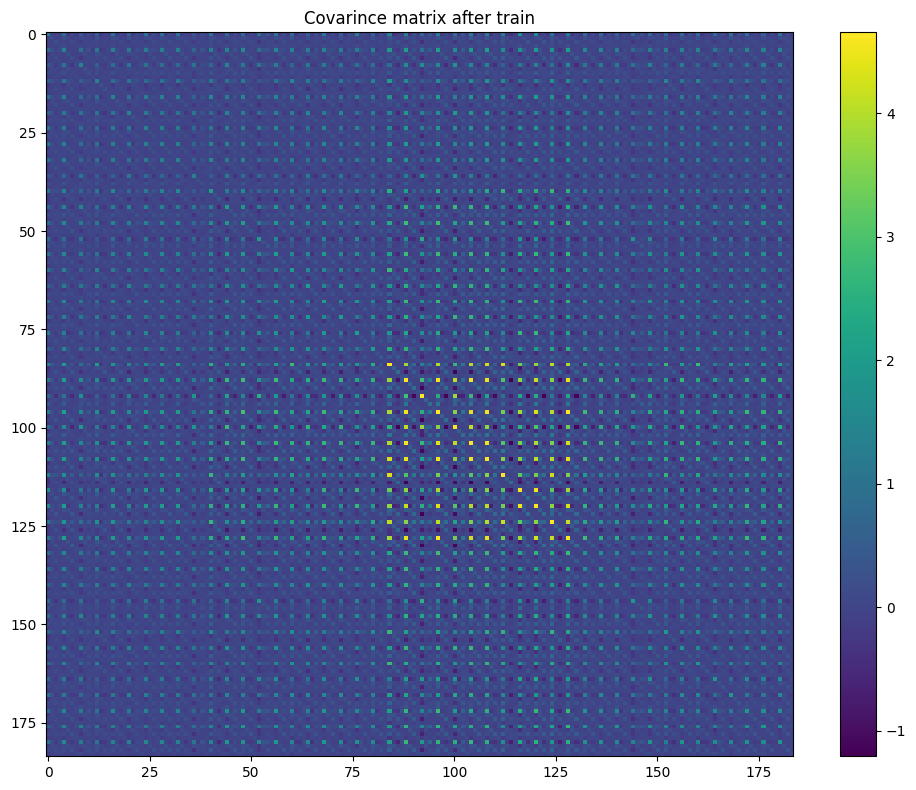

In [627]:
n = K_latent.shape[0]

plt.figure(figsize=(10,8))
plt.imshow(K_latent.detach().cpu().numpy(), aspect="auto")
plt.colorbar()
plt.title("Covarince matrix after train")
plt.tight_layout()
plt.show()

In [628]:
# cuts = [0, 40, 100, 180, 220]
# for i in range(4):
#     for j in range(4):
#         Bij = K[cuts[i]:cuts[i+1], cuts[j]:cuts[j+1]]
#         print(i, j, "block norm  =", torch.linalg.norm(Bij).item())

In [629]:
# def permute_interleaved_to_channel_major(K, N, d):
#     Dout = d + 1
#     perm = []
#     for c in range(Dout):
#         for i in range(N):
#             perm.append(i*Dout + c)
#     perm = torch.tensor(perm, device=K.device)
#     return K[perm][:, perm]

# N = 55
# K_re = permute_interleaved_to_channel_major(K_latent, N=N, d=3)


In [630]:
# plt.figure(figsize=(10,8))
# plt.imshow(K_re.detach().cpu().numpy(), aspect="auto")
# plt.colorbar()
# plt.title("Covarince matrix after train")
# plt.tight_layout()
# plt.show()

In [631]:
def rmse(a, b):
    return torch.sqrt(torch.mean((a - b) ** 2)).item()

def task_truth(t, X):
    q1, g1 = q1_and_grad(X)
    q2, g2 = q2_and_grad(X)
    a, b = mixing[t, 0], mixing[t, 1]
    return a*q1 + b*q2, a*g1 + b*g2

In [632]:
N_test = 100
rmse_vals = []
rmse_grads = []

In [ ]:
with torch.no_grad(), gpytorch.settings.fast_pred_var():
    for t in range(K):
        X_test = make_inputs(N_test, d)

        # build augmented test input with task id
        # just plug in to the model -> naturall handle the task

        X_test_aug = torch.cat(
            [X_test, torch.full((N_test, 1), float(t), device=device, dtype=dtype)],
            dim=1
        )

        # latent posterior over [f, grads] (noise-free output)
        post = model(X_test_aug)
        mean_mat = post.mean.view(N_test, d + 1)

        f_pred = mean_mat[:, 0]
        g_pred = mean_mat[:, 1:]

        f_true, g_true = task_truth(t, X_test)

        print(f"task {t} - rmse(f_true) = {rmse(f_pred, f_true):.6f}")
        print(f"task {t} - rmse(grad_true) = {rmse(g_pred, g_true):.6f}\n")

task 0 - rmse(f_true) = 0.036027
task 0 - rmse(grad_true) = 0.057925

task 1 - rmse(f_true) = 0.074439
task 1 - rmse(grad_true) = 0.086080

task 2 - rmse(f_true) = 0.149673
task 2 - rmse(grad_true) = 0.150640

task 3 - rmse(f_true) = 0.080212
task 3 - rmse(grad_true) = 0.093278



In [634]:
## parameters after train
for name, param in model.named_parameters():
    print(name, param.shape, param.detach().cpu())

raw_val_noise torch.Size([4]) tensor([-6.5353, -6.5833, -6.5675, -6.6715])
raw_grad_noise torch.Size([4]) tensor([-7.0163, -6.8969, -6.7831, -6.8485])
likelihood.noise_covar.raw_noise torch.Size([1]) tensor([-inf])
mean_module.constant torch.Size([1]) tensor([3.5061])
covar_module.raw_outputscale torch.Size([]) tensor(-1.9517)
covar_module.base_kernel.task_kernels.0.covar_factor torch.Size([4, 2]) tensor([[-4.8641e-03,  1.3706e-07],
        [ 3.5958e-03,  3.3934e-07],
        [-6.8378e-04,  2.5482e-07],
        [ 1.5367e-04,  2.3990e-07]])
covar_module.base_kernel.task_kernels.0.raw_var torch.Size([4]) tensor([-4.9544, -4.0831, -4.1119, -3.9453])
covar_module.base_kernel.task_kernels.1.covar_factor torch.Size([4, 2]) tensor([[0.0295, 2.0777],
        [0.0734, 1.5241],
        [1.8520, 1.3094],
        [0.5134, 1.8569]])
covar_module.base_kernel.task_kernels.1.raw_var torch.Size([4]) tensor([-2.5352, -2.6126, -1.3662, -3.9890])
covar_module.base_kernel.task_kernels.2.covar_factor torch.

In [ ]:
base = model.covar_module.base_kernel

for q, ik in enumerate(base.task_kernels):
    print(f"\nlatent q={q} task kernel params:")
    for n, p in ik.named_parameters():
        print(" ", n, p.detach().cpu())


latent q=0 task kernel params:
  covar_factor tensor([[-4.8641e-03,  1.3706e-07],
        [ 3.5958e-03,  3.3934e-07],
        [-6.8378e-04,  2.5482e-07],
        [ 1.5367e-04,  2.3990e-07]])
  raw_var tensor([-4.9544, -4.0831, -4.1119, -3.9453])

latent q=1 task kernel params:
  covar_factor tensor([[0.0295, 2.0777],
        [0.0734, 1.5241],
        [1.8520, 1.3094],
        [0.5134, 1.8569]])
  raw_var tensor([-2.5352, -2.6126, -1.3662, -3.9890])

latent q=2 task kernel params:
  covar_factor tensor([[ 0.0008, -0.0013],
        [ 0.0010, -0.0016],
        [ 0.0011, -0.0021],
        [ 0.0009, -0.0015]])
  raw_var tensor([-3.5624, -4.3443, -3.4336, -4.8403])

latent q=3 task kernel params:
  covar_factor tensor([[ 1.8610, -1.6119],
        [ 2.6970, -2.3907],
        [ 4.0892, -3.5873],
        [ 2.4614, -2.1378]])
  raw_var tensor([-4.6867, -3.1487, -3.4239, -5.4008])


In [636]:
# learn independent noise for task val and partial derivative val
if hasattr(model, "raw_val_noise"):
    val_var  = F.softplus(model.raw_val_noise).detach().cpu()

    grad_var = F.softplus(model.raw_grad_noise).detach().cpu()
    
    print("\nlearned val std per task:", torch.sqrt(val_var))
    
    print("learned grad std per task:", torch.sqrt(grad_var))


learned val std per task: tensor([0.0381, 0.0372, 0.0375, 0.0356])
learned grad std per task: tensor([0.0299, 0.0318, 0.0336, 0.0326])
